# 01 · Forecasting data audit (US Embassy station, OpenAQ 8160)

**Goal:** check that the hourly PM2.5 record is good enough for next-day forecasting, and lock the decisions the models depend on.

**Needs:** OpenAQ archive files for location 8160 anywhere under `data/raw/pm25/` (e.g. `data/raw/pm25/openaq/8160/`).
For a dry run without real data: `python scripts/make_synthetic_data.py` from the repo root (fake data, delete it afterwards).

All logic lives in `src/uaq/` (`io.py`, `daily.py`, `audit_forecast.py`, `thresholds.py`, `baselines.py`); this notebook runs it step by step.

In [1]:
# Setup: works whether or not you ran `pip install -e .`
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().resolve().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from uaq.config import load_config, ROOT
cfg = load_config()
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
%matplotlib inline
print("Project root:", ROOT)

Project root: /Users/user/Desktop/neural


## 1 · Study design from the config
Every date here is locked. The test winter (2024/25) is never scored in this notebook.

In [2]:
fp = cfg["forecast"]["periods"]
display(pd.DataFrame(fp["split"]).T.rename_axis("split"))
print("Core:", fp["core"], "| Pre-ban sensitivity:", fp["pre_ban_sensitivity"])
print("Smog season months:", cfg["smog_months"], "| Raw-coal ban:", cfg["structural_break"])

,start,end
split,,
train,2019-07-01,2023-06-30
val,2023-07-01,2024-06-30
test,2024-07-01,2025-03-31


Core: {'start': '2019-07-01', 'end': '2025-03-31'} | Pre-ban sensitivity: {'start': '2016-11-09', 'end': '2019-06-30'}
Smog season months: [11, 12, 1, 2] | Raw-coal ban: 2019-05-15


## 2 · Load the hourly data
Timestamps are converted to Ulaanbaatar local time. Negative values become missing; values above the plausibility bound are **flagged, not deleted**, because winter peaks are genuinely extreme.

In [3]:
from uaq.io import load_hourly
hourly = load_hourly(cfg)
print(hourly.attrs)
print("Rows:", len(hourly), "| from", hourly["ts_local"].min(), "to", hourly["ts_local"].max())
hourly.head()

{'files': 3181, 'units_seen': ['µg/m³'], 'dropped_bad_timestamps': 0, 'duplicate_station_hours': 0}
Rows: 61607 | from 2016-11-09 17:00:00 to 2025-03-04 12:00:00


,station_id,ts_local,station_name,pm25,lat,lon,flag_implausible
0,8160,2016-11-09 17:00:00,US Diplomatic Post: Ulaanbaatar-8160,30.3,47.928387,106.92947,False
1,8160,2016-11-09 18:00:00,US Diplomatic Post: Ulaanbaatar-8160,24.6,47.928387,106.92947,False
2,8160,2016-11-09 19:00:00,US Diplomatic Post: Ulaanbaatar-8160,35.3,47.928387,106.92947,False
3,8160,2016-11-09 20:00:00,US Diplomatic Post: Ulaanbaatar-8160,36.6,47.928387,106.92947,False
4,8160,2016-11-09 21:00:00,US Diplomatic Post: Ulaanbaatar-8160,29.8,47.928387,106.92947,False


## 3 · Hourly → daily means
A day counts only if at least 18 of 24 hours were observed; otherwise it is **missing**, never treated as clean air.

In [5]:
from uaq.daily import to_daily
daily = to_daily(hourly, cfg["quality"]["min_hours_per_day"])
print(f"Valid days: {daily['valid'].sum()} of {len(daily)} ({daily['valid'].mean():.1%})")
daily[["n_hours", "pm25_daily", "max_hourly"]].describe().round(1)

Valid days: 1835 of 3038 (60.4%)


,n_hours,pm25_daily,max_hourly
count,3038.0,1835.0,2250.0
mean,15.5,66.5,186.0
std,10.2,70.9,192.9
min,0.0,0.0,0.0
25%,0.0,16.6,43.0
50%,22.0,38.8,112.0
75%,24.0,93.4,277.0
max,24.0,503.5,985.0


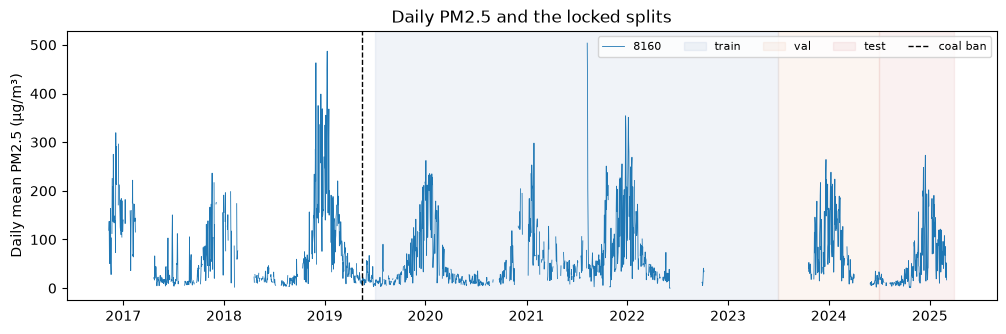

In [6]:
from uaq.periods import assign_split
fig, ax = plt.subplots(figsize=(12, 3.5))
for sid, g in daily.groupby("station_id"):
    ax.plot(g["date"], g["pm25_daily"], lw=0.6, label=sid)
colors = {"train": "#4C72B0", "val": "#DD8452", "test": "#C44E52"}
for name, s in fp["split"].items():
    ax.axvspan(pd.Timestamp(s["start"]), pd.Timestamp(s["end"]), color=colors[name], alpha=0.08, label=name)
ax.axvline(pd.Timestamp(cfg["structural_break"]), color="k", ls="--", lw=1, label="coal ban")
ax.set_ylabel("Daily mean PM2.5 (µg/m³)"); ax.legend(ncol=5, fontsize=8); ax.set_title("Daily PM2.5 and the locked splits")
plt.show()

## 4 · Coverage by smog season
Share of Nov–Feb days with a valid daily mean. The station is usable if training holds at least 240 valid smog-season days in total (two full winters’ worth; partial winters count, because the model trains on every valid day) and the validation and test winters each have ≥75% coverage. good_train_winters is reported for the write-up only.

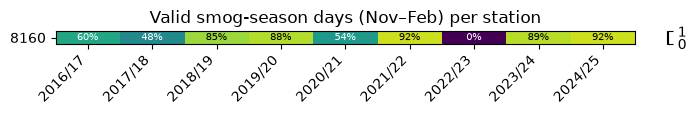

,good_train_winters,train_valid_smog_days,val_cov,test_cov_min,eligible
station_id,,,,,
8160,2,283,0.893,0.925,True


In [7]:
from uaq import audit_forecast as af
cov = af.coverage_table(daily, cfg)
af.plot_coverage(cov, cfg["quality"]["min_valid_frac"]); plt.show()
elig = af.eligibility(cov, cfg)
elig

## 5 · Before and after the raw-coal ban
Why the core study starts in July 2019: the level shifts at the ban, so pre-ban winters are kept only for the optional sensitivity experiment (H5).

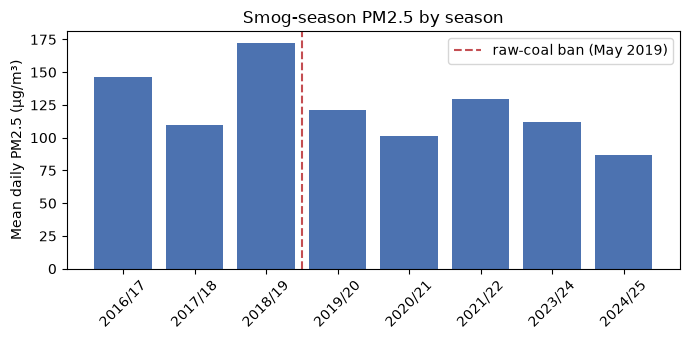

In [8]:
af.plot_season_means(daily, cfg); plt.show()

## 6 · Daily cycle in winter
Motivates the hourly features (yesterday evening's mean and maximum). Hours are local time.

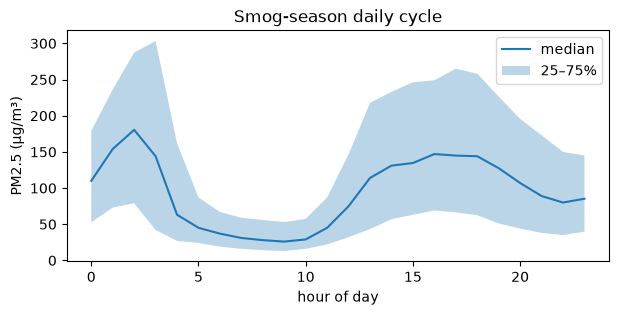

In [9]:
from uaq.periods import in_months
h = hourly[in_months(hourly["ts_local"].dt.tz_localize(None), cfg["smog_months"]).values]
prof = h.groupby(h["ts_local"].dt.hour)["pm25"].quantile([0.25, 0.5, 0.75]).unstack()
ax = prof[0.5].plot(figsize=(7, 3), label="median")
ax.fill_between(prof.index, prof[0.25], prof[0.75], alpha=0.3, label="25–75%")
ax.set_xlabel("hour of day"); ax.set_ylabel("PM2.5 (µg/m³)"); ax.legend(); ax.set_title("Smog-season daily cycle")
plt.show()

## 7 · Event threshold (training smog-season days only)
Rule: the lowest official line exceeded on ≤60% of training days; otherwise the training 75th percentile, labelled study-defined.

In [10]:
from uaq import thresholds
rates = af.threshold_table(daily, cfg)
display(rates.round(3))
thr_name, thr, why = thresholds.choose(rates, cfg)
print(f"Chosen: {thr_name} = {thr} µg/m³\n{why}")

,threshold,ug_m3,base_rate
0,mns_4585_2025,37.5,0.894
1,mns_4585_2016,50.0,0.813
2,who_it1_2021,75.0,0.661
3,train_p75,170.8,0.251


Chosen: train_p75 = 170.8 µg/m³
Every official threshold is exceeded too often in training (mns_4585_2025 89%, mns_4585_2016 81%, who_it1_2021 66%), so a study-defined training percentile is used. Report the official rates as context.


## 8 · Baselines the neural networks must beat
Persistence (tomorrow = today), 3-day mean, and climatology (fitted on training only). Validation scores are the bar; the test winter is not scored here.

In [11]:
stations = elig.index[elig["eligible"]].tolist()
scores = af.baseline_scores(daily, stations, thr, cfg)
scores.round(3)

,group,model,n,mae,rmse,r2,events,base_rate,tp,false_alarms,missed,precision,recall,f1
0,train,persistence,263,48.460,66.033,0.170,68,0.259,39,29,29,0.574,0.574,0.574
1,val,persistence,105,49.240,62.469,-0.018,22,0.210,8,14,14,0.364,0.364,0.364
2,train,mean3d,274,50.943,67.009,0.140,70,0.255,33,19,37,0.635,0.471,0.541
3,val,mean3d,106,51.166,61.576,0.004,22,0.208,8,7,14,0.533,0.364,0.432
4,train,climatology,283,47.013,58.492,0.343,71,0.251,18,16,53,0.529,0.254,0.343
5,val,climatology,108,50.876,61.762,0.004,22,0.204,4,11,18,0.267,0.182,0.216


## 9 · Save the audit report
Writes `outputs/audit_forecast/audit_report.md` plus the tables and figures above.
Record the decisions (usable station, threshold, baseline scores) in the plan doc.

In [12]:
report = af.run()
print(report.read_text()[:1500])

# Forecasting data audit

- Raw files read: 3181
- Units seen: ['µg/m³'] (expected µg/m³)
- Hourly rows: 61,607 across 1 station(s)
- Date range: 2016-11-09 17:00:00 → 2025-03-04 12:00:00
- Duplicate station-hours merged: 0
- Unparseable timestamps dropped: 0
- Hourly values flagged implausible (>1500): 0

## Decisions

- **Usable station(s):** 8160
- **Event threshold:** train_p75 = 170.8 µg/m³. Every official threshold is exceeded too often in training (mns_4585_2025 89%, mns_4585_2016 81%, who_it1_2021 66%), so a study-defined training percentile is used. Report the official rates as context.
- **Splits:** train 2019-07-01→2023-06-30, val 2023-07-01→2024-06-30, test 2024-07-01→2025-03-31 (sealed).

## Station eligibility

|   station_id |   good_train_winters |   train_valid_smog_days |   val_cov |   test_cov_min | eligible   |
|-------------:|---------------------:|------------------------:|----------:|---------------:|:-----------|
|         8160 |                    2 |          